# DDET of white noise, and how far the chaos examples are from it

The `exrqa` examples compare every DDET value with white noise, which the paper puts at DDET ≈ −1. This notebook asks two questions:

* **Part A.** Is the DDET of white noise always −1, or some other fixed value? If not, what does it depend on?
* **Part B.** How far above their white-noise baseline are the four example systems (Lorenz, Rössler, Duffing, Mackey–Glass), with and without noise?

**Contents:** A1 realisations with the paper's settings · A2 a random-RP model · A3 settings that move the baseline · A4 where the model fails · A5 answer · B1 settings · B2 sweeps · B3 distance per system (DDET and DET) · B4 overall picture · B5 noise level (distance, and AUC against white and red noise) · B6 summary table · B7 conclusions

Runtime is about 8 minutes, mostly the parameter sweeps and the noise-level AUC of Part B.

In [1]:
import sys, pathlib, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

try:
    import exrqa as xr
except ImportError:                       # use the local package without installing it
    sys.path.insert(0, str(pathlib.Path.cwd().parent))
    import exrqa as xr

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.6, "grid.linestyle": "-",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "font.size": 10, "axes.titlesize": 10.5, "lines.linewidth": 1.8, "lines.markersize": 5,
    "legend.frameon": False, "legend.fontsize": 9,
})
INK, GREY = "#52514e", "#8f8e89"
# in this notebook colour identifies the system (Part B); Part A uses ink and grey only
SYSC = {"Lorenz": "#2a78d6", "Rössler": "#eb6834", "Duffing": "#1baf7a", "Mackey–Glass": "#eda100"}

## Part A. White noise

### A1. 100 realisations with the paper's settings

Gaussian white noise, N = 1000 embedded states, m = 3, τ = 10, ε = 5th percentile, τm = 10, `ws = tau_w = d_max = 2`: the settings of the paper's Lorenz study. The DDET is computed twice: over all windows (the paper's definition), and with `max_lag = N/2`, which drops the short windows near the RP corner.

100 realisations in 19 s
all windows (paper)  mean -1.034  sd 0.058  range -1.13 … -0.71  within ±0.1 of −1: 90%
max_lag = N/2        mean -1.031  sd 0.036  range -1.11 … -0.94  within ±0.1 of −1: 99%


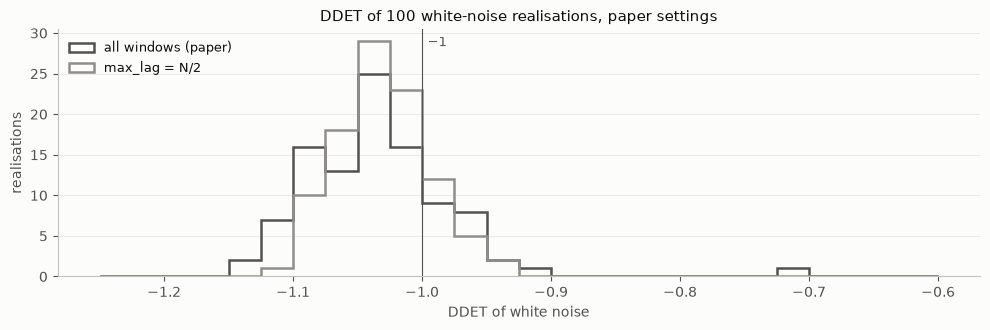

In [2]:
N = 1000

def noise_rp(x, m=3, tau=10, perc=5, tau_m=10, method="lm2p"):
    return xr.recurrence_plot(x, m=m, tau=tau, method=method, perc=perc, tau_m=tau_m)

def white(seed, n=N, m=3, tau=10):
    return np.random.default_rng(seed).standard_normal(n + (m - 1) * tau)

t0 = time.time()
full, half, rr = [], [], []
for seed in range(100):
    R = noise_rp(white(seed))
    d = xr.ddet(R)
    full.append(d.ddet); rr.append(d.rr_w.mean())
    half.append(xr.ddet(R, max_lag=N // 2).ddet)
full, half, rr = np.array(full), np.array(half), np.array(rr)
print(f"100 realisations in {time.time() - t0:.0f} s")
for name, v in [("all windows (paper)", full), ("max_lag = N/2", half)]:
    print(f"{name:20s} mean {v.mean():+.3f}  sd {v.std(ddof=1):.3f}  range {v.min():+.2f} … {v.max():+.2f}  "
          f"within ±0.1 of −1: {np.mean(np.abs(v + 1) <= 0.1):.0%}")

fig, ax = plt.subplots(figsize=(10, 3.4))
bins = np.linspace(-1.25, -0.6, 27)
ax.hist(full, bins, histtype="step", color=INK, lw=1.8, label="all windows (paper)")
ax.hist(half, bins, histtype="step", color=GREY, lw=1.8, label="max_lag = N/2")
ax.axvline(-1, color=INK, lw=0.8)
ax.annotate("−1", (-1, ax.get_ylim()[1]), xytext=(4, -12), textcoords="offset points", color=INK, fontsize=9)
ax.set(xlabel="DDET of white noise", ylabel="realisations", title="DDET of 100 white-noise realisations, paper settings")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
plt.tight_layout()

With the paper's settings white noise does give ≈ −1: mean −1.03, sd 0.06, and 90 % of the realisations lie within ±0.1 of −1. The one outlier at −0.71 comes from the short windows beyond lag N/2, near the RP corner. Dropping them (`max_lag = N/2`) removes it and narrows the spread to sd 0.04, with 99 % within ±0.1.

### A2. Why −1? A random-RP model

For white noise the cells of an LM2P plot are close to independent, with density $RR$. Take one window of `ws` diagonals:

* A row is "on" (the OR of its `ws` cells) with probability $q = ws \cdot RR$. Two minima of one row cannot both fall inside the window, so the probabilities add.
* The gaps $D$ between "on" rows are geometric, $P(D) = q(1-q)^{D-1}$. The connected fraction of the window is $c = q\sum_{D \le d_{max}} D\,q(1-q)^{D-1}$, and $DD_w = c/(1-c)$.

So

$$DDET_{noise} \approx \ln\frac{c}{(1-c)\,RR} \;\approx\; \ln\!\Big(ws^2\,\frac{d_{max}(d_{max}+1)}{2}\,RR\Big) \quad\text{for small } RR .$$

With `ws = d_max = 2` this is $\ln(12\,RR)$. The paper's settings give $RR \approx 0.03$, so $DDET \approx \ln 0.36 \approx -1$. **The −1 follows from the recurrence rate the settings produce. It is not a property of noise.**

The recurrence rate has a simple form for LMT. In a profile of independent values, a sample is a local minimum below the ε-quantile $e$ with probability $\int_0^e (1-u)^2\,du = [1-(1-e)^3]/3$, which is ≈ 0.048 for $e = 0.05$. LM2P then removes minima closer than τm to a deeper one, which lowers $RR$ to ≈ 0.03 for τm = 10.

`xr.ddet_iid(rr, ws, d_max)` evaluates the model. The cell below checks it three ways.

In [3]:
print(f"LM2P white noise: mean RR_w = {rr.mean():.4f}   ddet_iid = {xr.ddet_iid(rr.mean()):+.3f}   measured mean = {full.mean():+.3f}")

e = 0.05
lmt = [xr.ddet(noise_rp(white(s), method="lmt")) for s in range(10)]
lmt_rr = np.mean([d.rr_w.mean() for d in lmt])
print(f"LMT white noise:  mean RR_w = {lmt_rr:.4f}   formula [1-(1-e)^3]/3 = {(1 - (1 - e) ** 3) / 3:.4f}   "
      f"ddet_iid = {xr.ddet_iid(lmt_rr):+.3f}   measured = {np.mean([d.ddet for d in lmt]):+.3f}")

B = (np.random.default_rng(0).random((N, N)) < rr.mean()).astype(np.uint8)       # independent cells, same density
dB = xr.ddet(B)
print(f"random RP (independent cells): DDET = {dB.ddet:+.3f}   ddet_iid = {xr.ddet_iid(dB.rr_w.mean(), exclusive=False):+.3f}")

LM2P white noise: mean RR_w = 0.0304   ddet_iid = -1.038   measured mean = -1.034


LMT white noise:  mean RR_w = 0.0466   formula [1-(1-e)^3]/3 = 0.0475   ddet_iid = -0.620   measured = -0.618
random RP (independent cells): DDET = -1.132   ddet_iid = -1.062


The model reproduces the measured mean almost exactly (−1.038 against −1.034), and the LMT recurrence rate matches the formula (0.0466 against 0.0475). For an RP with truly independent cells the model is 0.07 too high. A window with K points has only K − 1 gaps, which the model ignores, and that matters in short windows. Treat the model as a good approximation (within ≈ 0.1), not an exact result.

### A3. Settings that move the baseline

One setting at a time is changed, the others stay at the paper's values. Each point is 10 white-noise realisations (mean ± 1 sd). The model line is `ddet_iid` evaluated at the measured RR, so it shows how much of the change is explained by RR alone. The vertical hairline marks the paper's value.

done in 41 s

ε percentile                1: -2.19±0.15  2: -1.63±0.09  5: -1.01±0.04  10: -0.64±0.03  20: -0.40±0.03
τm (2 is the same as LMT)   2: -0.59±0.04  3: -0.66±0.05  5: -0.78±0.05  10: -1.01±0.04  20: -1.37±0.05  40: -1.75±0.10
window size ws              1: -2.45±0.11  2: -1.01±0.04  3: -0.19±0.05  4: +0.39±0.04  6: +1.18±0.04  10: +2.24±0.04
d_max                       1: -1.98±0.10  2: -1.01±0.04  3: -0.36±0.06  5: +0.48±0.03
embedding dimension m       1: -0.96±0.03  2: -1.00±0.10  3: -1.01±0.04  5: -1.05±0.10  8: -1.07±0.12
RP size N                   250: -1.00±0.10  500: -1.03±0.05  1000: -1.01±0.04  2000: -1.03±0.04


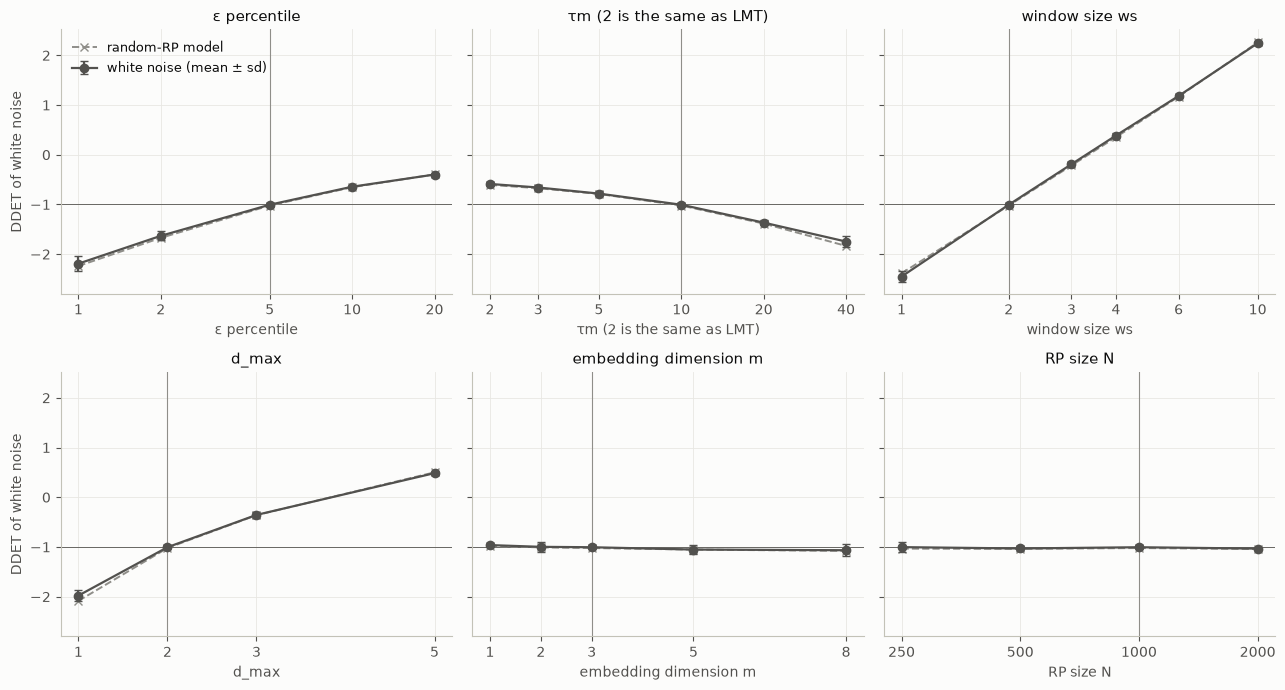

In [4]:
def measure(seeds=10, n=N, m=3, tau=10, perc=5, tau_m=10, ws=2, d_max=2, gen=None):
    vals, rrs = [], []
    for s in range(seeds):
        rng = np.random.default_rng(1000 + s)
        x = rng.standard_normal(n + (m - 1) * tau) if gen is None else gen(rng, n + (m - 1) * tau)
        d = xr.ddet(noise_rp(x, m, tau, perc, tau_m), ws=ws, d_max=d_max)
        vals.append(d.ddet); rrs.append(d.rr_w.mean())
    return np.mean(vals), np.std(vals, ddof=1), xr.ddet_iid(np.mean(rrs), ws, d_max)

base_R = [noise_rp(white(1000 + s)) for s in range(10)]          # reused when only the window changes
def measure_window(ws=2, d_max=2):
    ds = [xr.ddet(R, ws=ws, d_max=d_max) for R in base_R]
    v = np.array([d.ddet for d in ds])
    return v.mean(), v.std(ddof=1), xr.ddet_iid(np.mean([d.rr_w.mean() for d in ds]), ws, d_max)

t0 = time.time()
factors = {   # name: (values, paper value, log x-axis, function)
    "ε percentile":          ([1, 2, 5, 10, 20],      5,    True,  lambda v: measure(perc=v)),
    "τm (2 is the same as LMT)": ([2, 3, 5, 10, 20, 40], 10, True, lambda v: measure(tau_m=v)),
    "window size ws":        ([1, 2, 3, 4, 6, 10],    2,    True,  lambda v: measure_window(ws=v)),
    "d_max":                 ([1, 2, 3, 5],           2,    False, lambda v: measure_window(d_max=v)),
    "embedding dimension m": ([1, 2, 3, 5, 8],        3,    False, lambda v: measure(m=v)),
    "RP size N":             ([250, 500, 1000, 2000], 1000, True,  lambda v: measure(n=v)),
}
sens = {k: np.array([f(v) for v in vals]) for k, (vals, _, _, f) in factors.items()}
print(f"done in {time.time() - t0:.0f} s\n")

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
for ax, (k, (vals, paper, logx, _)) in zip(axes.flat, factors.items()):
    mean, sd, th = sens[k].T
    ax.axhline(-1, color=INK, lw=0.6)
    ax.axvline(paper, color=GREY, lw=0.8)
    ax.plot(vals, th, color=GREY, ls="--", lw=1.4, marker="x", ms=6, label="random-RP model")
    ax.errorbar(vals, mean, yerr=sd, color=INK, marker="o", ms=6, lw=1.6, capsize=3, label="white noise (mean ± sd)")
    if logx:
        ax.set_xscale("log")
    ax.set_xticks(vals, [str(v) for v in vals]); ax.minorticks_off()
    ax.set(xlabel=k, title=k)
    print(f"{k:28s}" + "  ".join(f"{v}: {mu:+.2f}±{s:.2f}" for v, (mu, s, _) in zip(vals, sens[k])))
for ax in axes[:, 0]:
    ax.set_ylabel("DDET of white noise")
axes[0, 0].legend(loc="upper left")
plt.tight_layout()

* **ws, d_max, ε and τm move the baseline a lot**: from −2.45 (ws = 1) to +2.24 (ws = 10), from −1.98 to +0.48 for d_max = 1…5, from −2.19 to −0.40 for the 1st to 20th percentile, and from −0.59 (LMT) to −1.75 for τm = 2…40. The model follows all of them. ε and τm act through RR, while ws and d_max act through the window.
* **m and N hardly change the mean** (−0.96 … −1.07). N sets the spread: sd 0.10 at N = 250, 0.04 at N = 1000–2000.
* With `ws = 10` white noise reaches DDET ≈ +2.2, higher than chaotic Lorenz with the paper's settings (≈ 0.7). A DDET value means little without a baseline computed with the same settings.

### A4. Where the model fails

The model assumes independent RP cells. Two common situations break that:

* **(a) Embedding delay τ ≤ `d_max`.** Embedded vectors $\tau$ samples apart share $m-1$ coordinates, so their distances are correlated along the diagonal. Gaps of length τ then become connected more often than chance.
* **(b) Coloured noise.** An AR(1) process $x_t = \phi\,x_{t-1} + \varepsilon_t$ has memory, so its RP has short diagonal structures.

Panel (c) checks independent noise with different amplitude distributions. The model should still work there, because only RR changes.

done in 29 s

tau          1: -0.30 (model -1.05)  2: +0.21 (model -1.06)  3: -1.02 (model -1.06)  5: -1.09 (model -1.05)  10: -1.01 (model -1.02)  20: -1.05 (model -1.04)
AR(1) phi    0.0: -1.03 (model -1.05)  0.3: -1.01 (model -1.07)  0.6: -0.84 (model -1.14)  0.8: -0.62 (model -1.34)  0.9: -0.46 (model -1.60)  0.95: -0.35 (model -1.84)
distribution Gaussian: -1.01 (model -1.02)  uniform: -0.94 (model -0.98)  Laplace: -1.07 (model -1.13)  exponential: -1.11 (model -1.11)  Student t (3 dof): -1.10 (model -1.10)  bimodal: -0.99 (model -1.00)


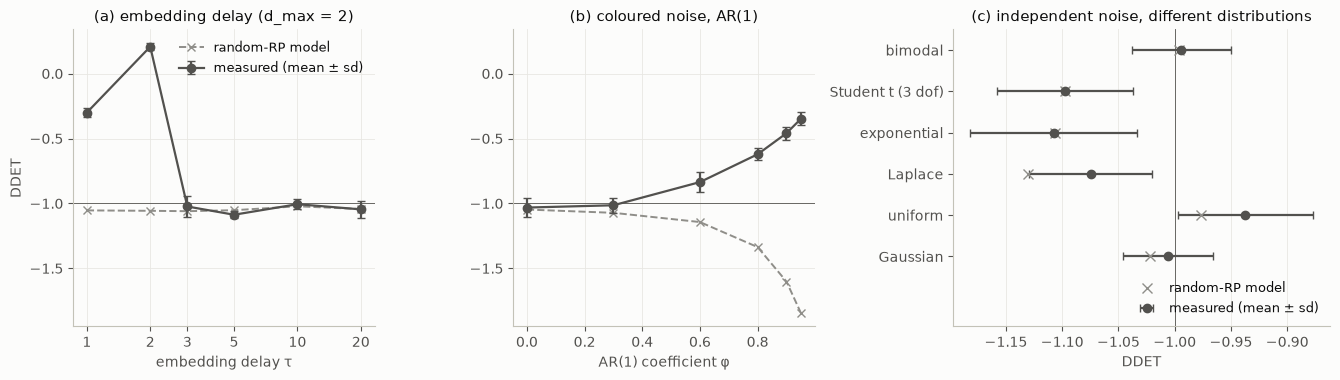

In [5]:
def ar1(phi):
    def gen(rng, n):
        e = rng.standard_normal(n + 500)
        x = np.empty_like(e); x[0] = e[0]
        for i in range(1, e.size):
            x[i] = phi * x[i - 1] + e[i]
        return x[500:]
    return gen

dists = {"Gaussian": None, "uniform": lambda r, n: r.uniform(-1, 1, n), "Laplace": lambda r, n: r.laplace(size=n),
         "exponential": lambda r, n: r.exponential(size=n), "Student t (3 dof)": lambda r, n: r.standard_t(3, n),
         "bimodal": lambda r, n: r.choice([-1.0, 1.0], n) + 0.3 * r.standard_normal(n)}
t0 = time.time()
taus, phis = [1, 2, 3, 5, 10, 20], [0.0, 0.3, 0.6, 0.8, 0.9, 0.95]
f_tau = np.array([measure(tau=t) for t in taus])
f_phi = np.array([measure(gen=ar1(p)) for p in phis])
f_dist = np.array([measure(gen=g) for g in dists.values()])
print(f"done in {time.time() - t0:.0f} s\n")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9), gridspec_kw={"width_ratios": [1, 1, 1.25]})
axes[1].sharey(axes[0])                                   # (a) and (b) share the DDET axis; (c) has categories
for ax, xs, res_, xl, title in [(axes[0], taus, f_tau, "embedding delay τ", "(a) embedding delay (d_max = 2)"),
                                (axes[1], phis, f_phi, "AR(1) coefficient φ", "(b) coloured noise, AR(1)")]:
    ax.axhline(-1, color=INK, lw=0.6)
    ax.plot(xs, res_[:, 2], color=GREY, ls="--", lw=1.4, marker="x", ms=6, label="random-RP model")
    ax.errorbar(xs, res_[:, 0], yerr=res_[:, 1], color=INK, marker="o", ms=6, lw=1.6, capsize=3, label="measured (mean ± sd)")
    ax.set(xlabel=xl, title=title)
axes[0].set_xscale("log"); axes[0].set_xticks(taus, [str(t) for t in taus]); axes[0].minorticks_off()
axes[0].set_ylabel("DDET")
axes[0].legend(loc="upper right")
ax = axes[2]
y = np.arange(len(dists))
ax.axvline(-1, color=INK, lw=0.6)
ax.errorbar(f_dist[:, 0], y, xerr=f_dist[:, 1], color=INK, marker="o", ms=6, lw=0, elinewidth=1.6, capsize=3, label="measured (mean ± sd)")
ax.plot(f_dist[:, 2], y, color=GREY, marker="x", ms=7, lw=0, label="random-RP model")
ax.set_yticks(y, list(dists)); ax.yaxis.set_tick_params(labelleft=True)
ax.set_ylim(-1.7, len(dists) - 0.5)                       # room for the legend below the last row
ax.set(xlabel="DDET", title="(c) independent noise, different distributions")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.tight_layout()

for name, xs, res_ in [("tau", taus, f_tau), ("AR(1) phi", phis, f_phi), ("distribution", list(dists), f_dist)]:
    print(f"{name:13s}" + "  ".join(f"{v}: {mu:+.2f} (model {th:+.2f})" for v, (mu, s, th) in zip(xs, res_)))

* **(a)** For τ = 1 and τ = 2 white noise reaches −0.30 and +0.21, far above the model (−1.05). From τ = 3 = `d_max` + 1 on, the model holds. Keep τ > `d_max`. The usual choice of τ (about a quarter period) gives that anyway for well-sampled signals.
* **(b)** Coloured noise is not white. DDET rises with the memory, to −0.84 at φ = 0.6 and −0.35 at φ = 0.95. The model only sees the falling RR and predicts lower values. Distance from *white* noise is therefore not distance from *any* noise. If your measurement noise has memory, also compare against coloured surrogates, for example AR or phase-randomised surrogates.
* **(c)** For independent noise the amplitude distribution shifts the value only slightly (−0.94 uniform … −1.11 exponential), and the model tracks the shift via RR to within 0.06.

### A5. Answer to question A

**No, −1 is not a universal value.** It is what the paper's settings produce: ε = 5th percentile and τm = 10 give white noise RR ≈ 0.03, and with `ws = d_max = 2` the DDET of a random RP is ≈ ln(12 · RR) ≈ −1.

* For independent noise, `xr.ddet_iid(RR, ws, d_max)` predicts the baseline to within ≈ 0.1. Over reasonable settings it ranges from about −2.5 to +2.2. Between realisations it varies with an sd of ≈ 0.04–0.1, depending on N.
* It is not a property of noise in general: coloured noise and an embedding delay τ ≤ `d_max` raise it.
* **Practical rule:** compute the baseline with your own settings and report the distance DDET − baseline. Use `xr.ddet_baseline(n=..., m=..., tau=..., tau_m=...)` for Gaussian white noise, or `xr.ddet_baseline(x=series, ...)` for shuffled surrogates of your series.

In [6]:
# the helper for your own work: the baseline for exactly your settings
b = xr.ddet_baseline(n=N + 20, m=3, tau=10, tau_m=10, n_real=20)     # Gaussian white noise
print("white noise:        ", {k: round(v, 3) for k, v in b.items() if k != "values"})
# with a series: shuffled surrogates (white noise with the series' amplitude distribution)
x = xr.add_noise(xr.zscore(xr.lorenz(N + 20, rho=80, dt=0.01)[:, 0]), 20, seed=1)
s = xr.ddet_baseline(x=x, m=3, tau=10, tau_m=10, n_real=20)
print("shuffled surrogates:", {k: round(v, 3) for k, v in s.items() if k != "values"})

white noise:         {'mean': -1.053, 'sd': 0.069, 'rr': 0.03, 'theory': -1.048}


shuffled surrogates: {'mean': -1.003, 'sd': 0.048, 'rr': 0.032, 'theory': -1.004}


## Part B. All examples against their white-noise baseline

### B1. Settings

Each system is analysed with the settings of its example notebook (N = 1000, ε = 5th percentile, `ws = tau_w = d_max = 2`):

| system | observable, sampling | m | τ | τm | sweep | chaotic / periodic reference |
|---|---|---|---|---|---|---|
| Lorenz | x, dt = 0.01 | 3 | 10 | 10 | ρ = 80…105 | ρ = 80 / 100 |
| Rössler (a = b = 0.2) | x, dt = 0.3 | 5 | 5 | 4 | c = 2.5…6.5 | c = 5.7 / 5.3 |
| Duffing (δ = 0.3, ω = 1.2) | x, 20 samples per forcing period | 5 | 5 | 8 | γ = 0.20…0.65 | γ = 0.5 / 0.37 |
| Mackey–Glass (n = 10) | x, dt = 1 | 5 | 6 | 8 | τ_d = 8…30 | τ_d = 17 / 14 |

The settings differ, so by Part A each system gets **its own baseline**: 20 Gaussian white-noise series analysed with that system's N, m, τ and τm (`xr.ddet_baseline`). The shuffled surrogates of the noisy chaotic reference signal are shown for comparison.

**Distance from white noise:** $\Delta DDET = DDET - \overline{DDET}_{noise}$. DDET is the log of a ratio, so $e^{\Delta DDET}$ is the factor by which the signal's $\langle DD_w\rangle/\langle RR_w\rangle$ exceeds that of white noise: ΔDDET = 2 means 7.4 times more connected diagonal structure than noise.

Periodic and chaotic parameter values are told apart from the bifurcation diagram, as in the example notebooks: a value is periodic when fewer than 25 % of its local maxima are distinct. For Lorenz the example notebook used the Lyapunov exponent instead, so the window edges can differ slightly.

In [7]:
N, FINE, N_BIF = 1000, 5, 3000
SYSTEMS = {   # sim(p, n, fine): x-component, n * fine samples every dt / fine (same RK4 step for every fine)
    "Lorenz": dict(pname="ρ", grid=np.round(np.arange(80, 105.01, 0.5), 2), m=3, tau=10, tau_m=10, chaos=80.0, per=100.0,
                   sim=lambda p, n, f=1: xr.lorenz(n * f, rho=p, dt=0.01 / f, substeps=10 // f, transient=2000 * f)[..., 0]),
    "Rössler": dict(pname="c", grid=np.round(np.arange(2.5, 6.501, 0.05), 3), m=5, tau=5, tau_m=4, chaos=5.7, per=5.3,
                    sim=lambda p, n, f=1: xr.rossler(n * f, c=p, dt=0.3 / f, substeps=10 // f, transient=2000 * f)[..., 0]),
    "Duffing": dict(pname="γ", grid=np.round(np.arange(0.20, 0.6501, 0.005), 3), m=5, tau=5, tau_m=8, chaos=0.5, per=0.37,
                    sim=lambda p, n, f=1: xr.duffing(n * f, gamma=p, dt=2 * np.pi / 1.2 / 20 / f, substeps=10 // f,
                                                     transient=2000 * f)[..., 0]),
    "Mackey–Glass": dict(pname="τ_d", grid=np.round(np.arange(8, 30.01, 0.25), 3), m=5, tau=6, tau_m=8, chaos=17.0, per=14.0,
                         sim=lambda p, n, f=1: xr.mackey_glass(n * f, tau=p, dt=1.0 / f, substeps=20 // f, transient=2000 * f)[..., 0]),
}

def lm2p(s, m, tau, tau_m):
    # DDET and DET of the same LM2P plot
    R = xr.recurrence_plot(s, m=m, tau=tau, method="lm2p", perc=5, tau_m=tau_m)
    return xr.ddet(R).ddet, xr.rqa(R)["DET"]

def lm2p_ddet(s, m, tau, tau_m):
    return lm2p(s, m, tau, tau_m)[0]

def det_baseline(n, m, tau, tau_m, n_real=20, seed=0):
    # DET of the same white-noise series that xr.ddet_baseline(n=n, ..., seed=seed) uses
    rng = np.random.default_rng(seed)
    v = np.array([lm2p(rng.standard_normal(n), m, tau, tau_m)[1] for _ in range(n_real)])
    return {"mean": float(v.mean()), "sd": float(v.std(ddof=1)), "values": v}

def shade(ax, grid, periodic):
    step = grid[1] - grid[0]
    edges = np.flatnonzero(np.diff(np.r_[0, periodic.astype(int), 0]))
    for a, b in zip(edges[::2], edges[1::2]):
        ax.axvspan(grid[a] - step / 2, grid[b - 1] + step / 2, color="#efeee9", lw=0, zorder=0)

def auc(v, periodic):
    a, b = v[periodic][:, None], v[~periodic][None, :]
    return float(np.mean((a > b) + 0.5 * (a == b)))

### B2. Sweeps and baselines

The same sweeps as in the example notebooks, with LM2P plots only: the signal without noise, and with 20 dB noise.

In [8]:
res = {}
t_all = time.time()
for name, c in SYSTEMS.items():
    t0 = time.time()
    m, tau, tau_m, grid = c["m"], c["tau"], c["tau_m"], c["grid"]
    n_raw = N + (m - 1) * tau
    long = c["sim"](grid, n_raw + N_BIF, FINE)                     # all parameter values at once
    sig = xr.zscore(long[:, : n_raw * FINE : FINE])                # RP signal
    tail = long[:, n_raw * FINE :]                                 # for the bifurcation diagram
    distinct = []
    for s in tail:
        p = xr.peak_values(s)
        distinct.append(np.unique(np.round(p / (1e-3 * s.std()))).size / p.size)
    clean, det_clean = np.array([lm2p(s, m, tau, tau_m) for s in sig]).T
    noisy, det_noisy = np.array([lm2p(xr.add_noise(s, 20, seed=n), m, tau, tau_m) for n, s in enumerate(sig)]).T
    base = xr.ddet_baseline(n=n_raw, m=m, tau=tau, tau_m=tau_m, n_real=20, seed=0)
    det_base = det_baseline(n_raw, m, tau, tau_m, n_real=20, seed=0)
    ref = xr.add_noise(xr.zscore(c["sim"](c["chaos"], n_raw)), 20, seed=1)
    surr = xr.ddet_baseline(x=ref, m=m, tau=tau, tau_m=tau_m, n_real=20, seed=0)
    res[name] = dict(periodic=np.array(distinct) < 0.25, clean=clean, noisy=noisy, base=base, surr=surr,
                     det_clean=det_clean, det_noisy=det_noisy, det_base=det_base)
    print(f"{name:13s} {len(grid):3d} values, {res[name]['periodic'].sum():2d} periodic | white noise {base['mean']:+.2f} ± {base['sd']:.2f} "
          f"(model {base['theory']:+.2f}) | shuffled surrogates {surr['mean']:+.2f} ± {surr['sd']:.2f}   [{time.time() - t0:.0f} s]")
print(f"all sweeps in {time.time() - t_all:.0f} s")

Lorenz         51 values,  4 periodic | white noise -1.05 ± 0.07 (model -1.05) | shuffled surrogates -1.00 ± 0.05   [19 s]


Rössler        81 values, 42 periodic | white noise -0.80 ± 0.05 (model -0.77) | shuffled surrogates -0.74 ± 0.04   [43 s]


Duffing        91 values, 37 periodic | white noise -1.05 ± 0.07 (model -1.02) | shuffled surrogates -0.91 ± 0.07   [40 s]


Mackey–Glass   89 values, 36 periodic | white noise -1.01 ± 0.08 (model -1.01) | shuffled surrogates -0.94 ± 0.05   [43 s]
all sweeps in 145 s


The matched baselines lie between −0.80 (Rössler) and −1.05. Rössler differs because its small τm = 4 leaves more noise minima, i.e. a higher RR (compare A3). The model predicts every baseline to within 0.03. The shuffled surrogates lie 0.05–0.14 higher than Gaussian white noise because they keep each system's non-Gaussian amplitude distribution (compare A4c). Using them as the baseline would lower every ΔDDET below by that much, which changes none of the conclusions.

### B3. Distance from white noise, per system

ΔDDET along each sweep. The zero line is the system's own white-noise baseline, and shading marks periodic parameter values. The y-axis is shared, so the four panels can be compared directly.

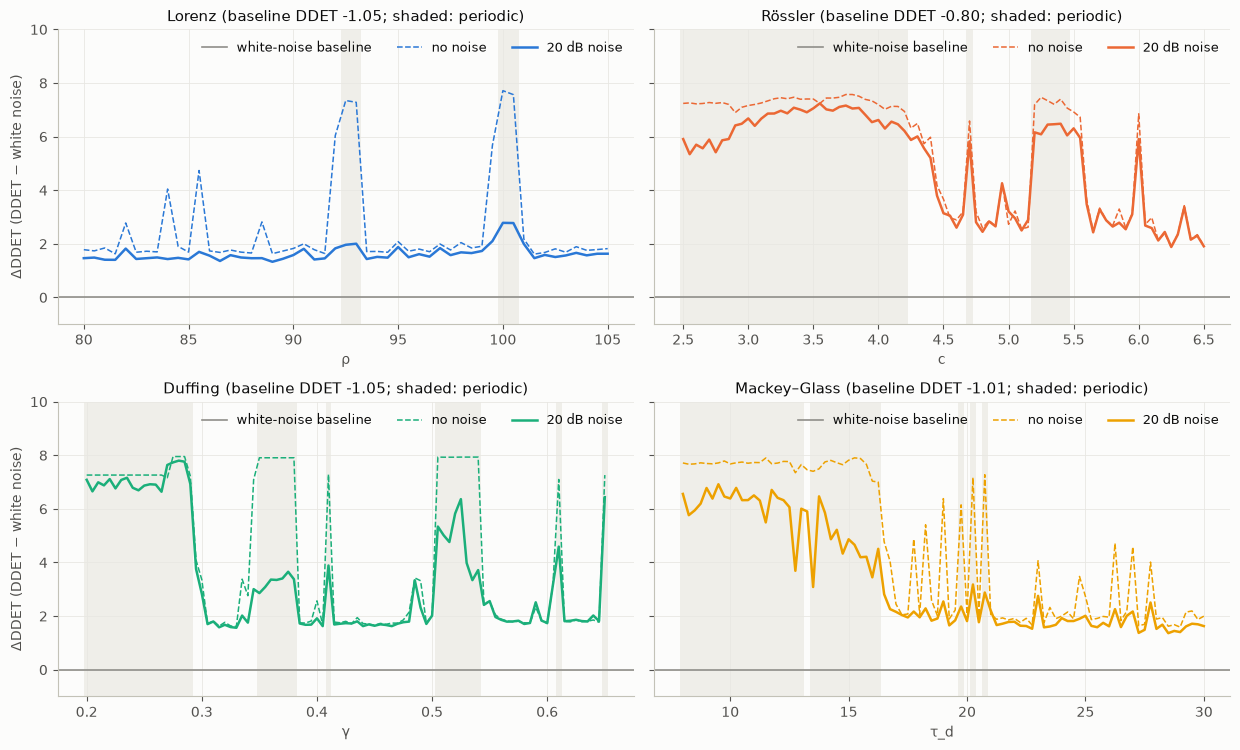

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.6), sharey=True)
for ax, (name, c) in zip(axes.flat, SYSTEMS.items()):
    r, grid = res[name], c["grid"]
    shade(ax, grid, r["periodic"])
    ax.axhline(0, color=GREY, lw=1.2, label="white-noise baseline")
    ax.plot(grid, r["clean"] - r["base"]["mean"], color=SYSC[name], lw=1.1, ls="--", label="no noise")
    ax.plot(grid, r["noisy"] - r["base"]["mean"], color=SYSC[name], lw=1.8, label="20 dB noise")
    ax.set(xlabel=c["pname"], title=f"{name} (baseline DDET {r['base']['mean']:+.2f}; shaded: periodic)")
    ax.legend(loc="upper right", ncol=3)
for ax in axes[:, 0]:
    ax.set_ylabel("ΔDDET (DDET − white noise)")
axes[0, 0].set_ylim(-1, 10)
plt.tight_layout()

**The same comparison for DET.** ΔDET = DET − DET of white noise, from the same LM2P plots and the same 20 white-noise series per system. DET is a fraction, so ΔDET is a plain difference: it can be at most 1 − baseline. The two figures have different units, so the table below also gives scale-free numbers: the closest chaotic value in white-noise standard deviations, and the AUC for telling periodic from chaotic values.

              white-noise DET |    ΔDET chaotic |   ΔDET periodic | closest chaotic, 20 dB (sd) |  AUC, 20 dB
                    mean ± sd |   clean   20 dB |   clean   20 dB |           DET          DDET |   DET  DDET
----------------------------------------------------------------------------------------------------
Lorenz           0.057 ± 0.003 |   +0.87   +0.22 |   +0.89   +0.27 |  +0.17 (  54)  +1.33 (  19) |  0.76  0.98
Rössler          0.074 ± 0.006 |   +0.87   +0.71 |   +0.88   +0.76 |  +0.63 ( 111)  +1.88 (  39) |  0.84  0.97
Duffing          0.057 ± 0.004 |   +0.89   +0.39 |   +0.94   +0.84 |  +0.28 (  68)  +1.56 (  23) |  0.93  0.99
Mackey–Glass     0.057 ± 0.004 |   +0.89   +0.26 |   +0.94   +0.72 |  +0.13 (  29)  +1.36 (  18) |  0.98  0.99

ΔDET columns are medians over the sweep. 'closest chaotic': smallest distance of any chaotic value with 20 dB noise,
in brackets in units of the white-noise sd of that measure. AUC: probability that a periodic value scores higher than

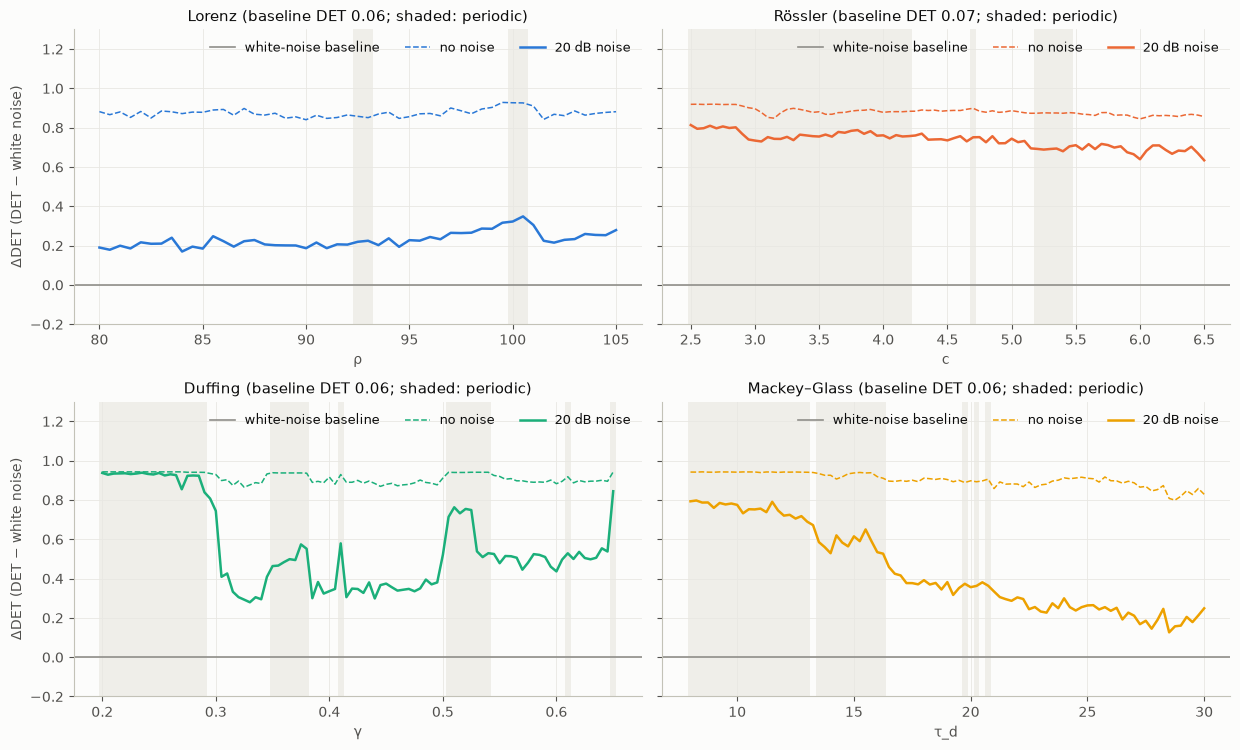

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.6), sharey=True)
for ax, (name, c) in zip(axes.flat, SYSTEMS.items()):
    r, grid = res[name], c["grid"]
    shade(ax, grid, r["periodic"])
    ax.axhline(0, color=GREY, lw=1.2, label="white-noise baseline")
    ax.plot(grid, r["det_clean"] - r["det_base"]["mean"], color=SYSC[name], lw=1.1, ls="--", label="no noise")
    ax.plot(grid, r["det_noisy"] - r["det_base"]["mean"], color=SYSC[name], lw=1.8, label="20 dB noise")
    ax.set(xlabel=c["pname"], title=f"{name} (baseline DET {r['det_base']['mean']:.2f}; shaded: periodic)")
    ax.legend(loc="upper right", ncol=3)
for ax in axes[:, 0]:
    ax.set_ylabel("ΔDET (DET − white noise)")
axes[0, 0].set_ylim(-0.2, 1.3)
plt.tight_layout()

print(f"{'':13s}{'white-noise DET':>16s} | {'ΔDET chaotic':>15s} | {'ΔDET periodic':>15s} | {'closest chaotic, 20 dB (sd)':>27s} | {'AUC, 20 dB':>11s}")
print(f"{'':13s}{'mean ± sd':>16s} | {'clean':>7s}{'20 dB':>8s} | {'clean':>7s}{'20 dB':>8s} | {'DET':>13s}{'DDET':>14s} | {'DET':>5s}{'DDET':>6s}")
print("-" * 100)
for name, r in res.items():
    b, per = r["det_base"], r["periodic"]
    dc, dn = r["det_clean"] - b["mean"], r["det_noisy"] - b["mean"]
    close_det, close_dd = dn[~per].min(), (r["noisy"] - r["base"]["mean"])[~per].min()
    print(f"{name:13s}{b['mean']:9.3f} ± {b['sd']:.3f} | {np.median(dc[~per]):+7.2f}{np.median(dn[~per]):+8.2f} | "
          f"{np.median(dc[per]):+7.2f}{np.median(dn[per]):+8.2f} | {close_det:+6.2f} ({close_det / b['sd']:4.0f}){close_dd:+7.2f} ({close_dd / r['base']['sd']:4.0f}) | "
          f"{auc(r['det_noisy'], per):5.2f}{auc(r['noisy'], per):6.2f}")
print("\nΔDET columns are medians over the sweep. 'closest chaotic': smallest distance of any chaotic value with 20 dB noise,"
      "\nin brackets in units of the white-noise sd of that measure. AUC: probability that a periodic value scores higher than a chaotic one.")

* **DET also puts every chaotic signal clearly above white noise.** LM2P plots of white noise contain almost no diagonal lines (DET ≈ 0.06, sd ≤ 0.006). The lowest chaotic ΔDET with 20 dB noise (+0.13, Mackey–Glass) is therefore still 29 noise standard deviations away. Measured that way, DET is even further from noise than DDET (29–111 against 18–39 sd). For the question "deterministic or white noise?" alone, both measures work in these examples. Against red noise, DET fails much earlier than DDET (B5).
* **Without noise, DET saturates.** ΔDET is ≈ +0.85 … +0.95 over all four sweeps, with medians of +0.87–0.89 for chaotic and +0.88–0.94 for periodic values. DET says the signal is deterministic, but not whether it is periodic or chaotic. In the ΔDDET figure above the two regimes differ by about 5.
* **Noise removes most of DET's distance.** With 20 dB noise the chaotic medians fall to +0.22 (Lorenz), +0.26 (Mackey–Glass) and +0.39 (Duffing), which is 25–44 % of their clean distance. Rössler keeps 82 % (+0.71). ΔDDET keeps 85–99 % (B6).
* **DET separates periodic from chaotic values only where noise hits the two regimes differently.** That works for Duffing (AUC 0.93) and for Mackey–Glass (0.98), whose DET falls steadily as the attractor gets more complex. The periodic windows of Lorenz (0.76) and Rössler (0.84) barely show. DDET reaches 0.97–0.99 for all four systems.

### B4. The overall picture

Every parameter value of the four sweeps as one dot, split into chaotic (circles) and periodic (squares). The black bar is the median.

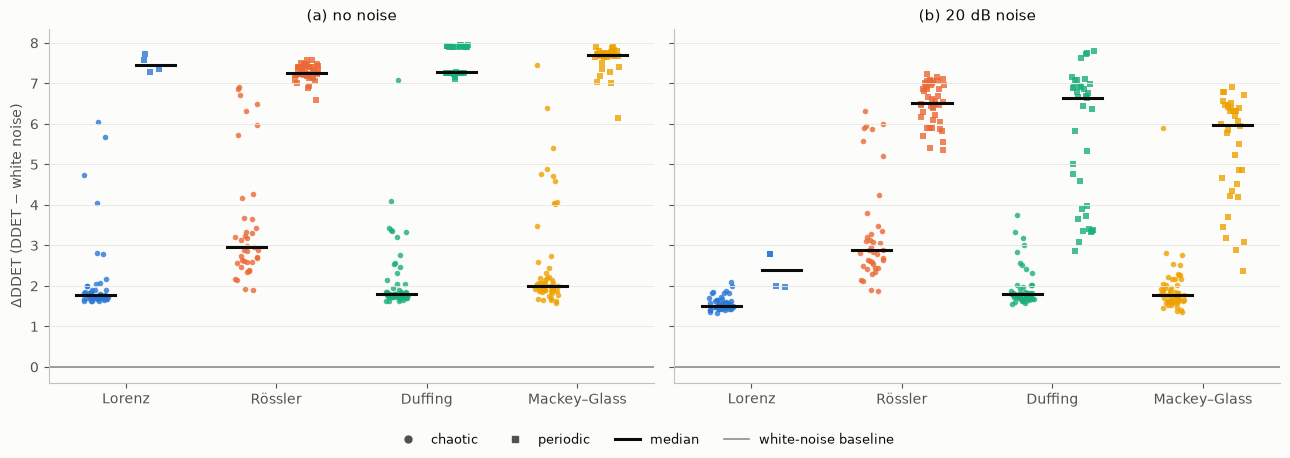

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, key, title in [(axes[0], "clean", "(a) no noise"), (axes[1], "noisy", "(b) 20 dB noise")]:
    ax.axhline(0, color=GREY, lw=1.2)
    for i, name in enumerate(SYSTEMS):
        r = res[name]
        v = r[key] - r["base"]["mean"]
        for off, sel, mk in [(-0.2, ~r["periodic"], "o"), (0.2, r["periodic"], "s")]:
            jit = np.random.default_rng(i).uniform(-0.08, 0.08, sel.sum())
            ax.scatter(i + off + jit, v[sel], s=16, marker=mk, color=SYSC[name], alpha=0.8, lw=0)
            ax.plot([i + off - 0.13, i + off + 0.13], [np.median(v[sel])] * 2, color="#0b0b0b", lw=2.2)
    ax.set_xticks(range(len(SYSTEMS)), list(SYSTEMS))
    ax.grid(axis="x", visible=False)
    ax.set_title(title)
axes[0].set_ylabel("ΔDDET (DDET − white noise)")
handles = [Line2D([], [], color=INK, marker="o", lw=0, label="chaotic"), Line2D([], [], color=INK, marker="s", lw=0, label="periodic"),
           Line2D([], [], color="#0b0b0b", lw=2.2, label="median"), Line2D([], [], color=GREY, lw=1.2, label="white-noise baseline")]
fig.legend(handles=handles, loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.07, 1, 1))

* **Every chaotic value of every system stays well above white noise**, including with 20 dB noise. The medians are +1.5 (Lorenz) to +2.9 (Rössler). The closest any chaotic value comes is +1.33 (Lorenz), which is 18–39 white-noise standard deviations depending on the system (table in B6). In ratio terms, the chaotic signals have about 4–18 times the connected diagonal structure of noise.
* **Periodic orbits are far higher without noise** (medians +7.3 to +7.7, about 1500–2200 times noise). With noise they drop the most, but for Rössler, Duffing and Mackey–Glass they stay above the chaotic values (medians +6.0 to +6.6).
* **Lorenz is the exception.** With noise its periodic windows drop to +2.4, close to its chaotic values. It is the only system analysed with the paper's settings (m = 3, about 40 samples per oscillation). Section 6 of the other example notebooks found that exactly these choices shrink the periodic–chaotic gap under noise.
* Chaotic Rössler sits highest (phase-coherent chaos), chaotic Lorenz lowest. The scattered high chaotic values without noise come from narrow windows, band chaos and the corner-window spikes discussed in the example notebooks.

### B5. How fast does noise close the gap?

ΔDDET of each system's chaotic and periodic reference signal as the noise grows (LM2P, same seeds as in the example notebooks). The left-most point is the signal without noise. A curve reaching 0 means the signal can no longer be told apart from white noise.

chaotic ΔDDET at no noise, 30, 25, 20, 15, 10, 5 dB
   Lorenz        [1.78 1.8  1.67 1.38 0.99 0.62 0.37]
   Rössler       [3.25 3.26 3.24 2.79 2.49 1.77 0.96]
   Duffing       [2.04 2.07 2.08 2.03 1.81 1.31 0.77]
   Mackey–Glass  [2.44 2.59 2.3  2.08 1.66 1.24 0.72]
periodic ΔDDET at no noise, 30, 25, 20, 15, 10, 5 dB
   Lorenz        [7.72 6.4  4.19 2.57 1.58 0.96 0.46]
   Rössler       [7.33 7.16 6.92 6.19 4.05 2.25 1.03]
   Duffing       [7.91 7.5  5.27 3.35 2.   1.01 0.63]
   Mackey–Glass  [7.75 7.63 7.2  6.08 2.74 1.64 0.94]


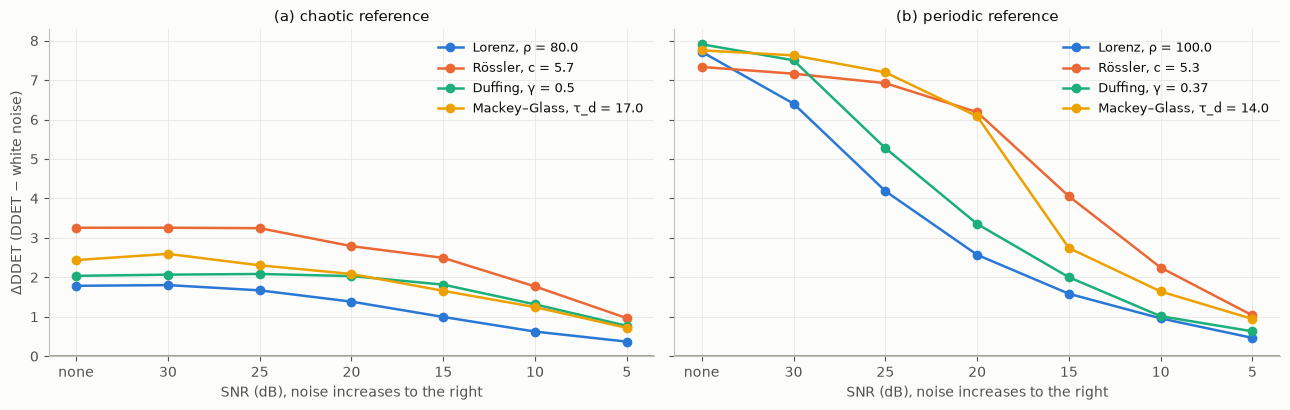

In [12]:
snrs = [30, 25, 20, 15, 10, 5]
xpos = [35] + snrs                                                   # 35 stands for "no noise"
snr_res = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True, sharey=True)
for name, c in SYSTEMS.items():
    m, tau, tau_m = c["m"], c["tau"], c["tau_m"]
    pair = xr.zscore(c["sim"](np.array([c["chaos"], c["per"]]), N + (m - 1) * tau))
    for ax, s, reg in zip(axes, pair, ["chaos", "per"]):
        v = [lm2p_ddet(s, m, tau, tau_m)] + [lm2p_ddet(xr.add_noise(s, snr, seed=3), m, tau, tau_m) for snr in snrs]
        v = np.array(v) - res[name]["base"]["mean"]
        snr_res[(name, reg)] = v
        ax.plot(xpos, v, color=SYSC[name], marker="o", ms=6, label=f"{name}, {c['pname']} = {c[reg]}")
for ax, title in zip(axes, ["(a) chaotic reference", "(b) periodic reference"]):
    ax.axhline(0, color=GREY, lw=1.2)
    ax.set_xticks(xpos, ["none"] + [str(v) for v in snrs])
    ax.set(xlabel="SNR (dB), noise increases to the right", title=title)
    ax.legend(loc="upper right")
axes[0].invert_xaxis()                                              # x is shared, so both panels flip
axes[0].set_ylabel("ΔDDET (DDET − white noise)")
plt.tight_layout()
for reg in ["chaos", "per"]:
    print({"chaos": "chaotic", "per": "periodic"}[reg], "ΔDDET at no noise, " + ", ".join(map(str, snrs)) + " dB")
    for name in SYSTEMS:
        print(f"   {name:13s}", np.round(snr_res[(name, reg)], 2))

* **Chaotic signals keep a positive distance down to 5 dB**, from +0.37 (Lorenz) to +0.96 (Rössler). At 10 dB all four are still +0.6 to +1.8 above white noise, many white-noise standard deviations. The question "deterministic or noise?" can therefore be answered at much higher noise levels than "periodic or chaotic?".
* **Periodic signals fall much faster.** Between 25 and 15 dB they lose most of their distance: Lorenz goes from +4.19 to +1.58, Duffing from +5.27 to +2.00. Rössler and Mackey–Glass hold up longest (+6.19 and +6.08 at 20 dB).
* At 10 dB, periodic and chaotic distances are within ≈ 0.5 of each other for every system. That is consistent with the paper's conclusion that DDET stops telling the regimes apart below ≈ 15 dB.

**Signal or noise? AUC across noise levels.** The curves above use one noisy realisation per level. Here each chaotic reference signal is cut into 20 segments of the same length (N embedded states), each segment gets its own noise, and the 20 values are compared with 20 noise series analysed with the same settings. The chaotic signals are used because an irregular chaotic signal is the case that can be mistaken for noise. Two kinds of noise serve as the reference:

* **white noise**: the 20 baseline series of B2;
* **red noise**: AR(1) noise $x_t = \varphi\,x_{t-1} + e_t$ with the same lag-1 autocorrelation $\varphi$ as the noisy signal, the usual "red noise" null hypothesis. $\varphi$ falls from ≈ 0.93–0.99 at 20 dB to ≈ 0.25 at −5 dB, because the added white noise breaks up the signal's smoothness.

AUC is the probability that a signal segment scores higher than a noise series. 1 means the signal is always recognised, 0.5 is chance, and below 0.5 the noise looks *more* deterministic than the signal. Markers are shifted slightly sideways so that overlapping values at 1.00 stay visible.

done in 164 s

AUC against white noise, DDET/DET
                      20 dB      15 dB      10 dB       5 dB       0 dB      -5 dB
   Lorenz         1.00/1.00  1.00/1.00  1.00/1.00  1.00/1.00  0.92/0.87  0.55/0.46
   Rössler        1.00/1.00  1.00/1.00  1.00/1.00  1.00/1.00  1.00/1.00  0.89/0.80
   Duffing        1.00/1.00  1.00/1.00  1.00/1.00  1.00/1.00  1.00/0.99  0.69/0.44
   Mackey–Glass   1.00/1.00  1.00/1.00  1.00/1.00  1.00/1.00  1.00/0.99  0.59/0.56

AUC against red noise, DDET/DET
                      20 dB      15 dB      10 dB       5 dB       0 dB      -5 dB
   Lorenz         1.00/1.00  1.00/0.98  0.83/0.00  0.48/0.00  0.50/0.01  0.31/0.14
   Rössler        1.00/1.00  1.00/1.00  1.00/1.00  1.00/1.00  1.00/0.99  0.78/0.68
   Duffing        1.00/1.00  1.00/1.00  1.00/1.00  1.00/0.91  0.94/0.41  0.51/0.23
   Mackey–Glass   1.00/1.00  1.00/1.00  1.00/1.00  1.00/0.98  0.92/0.54  0.51/0.37

mean DDET, signal/red noise
                        20 dB        15 dB        10 dB    

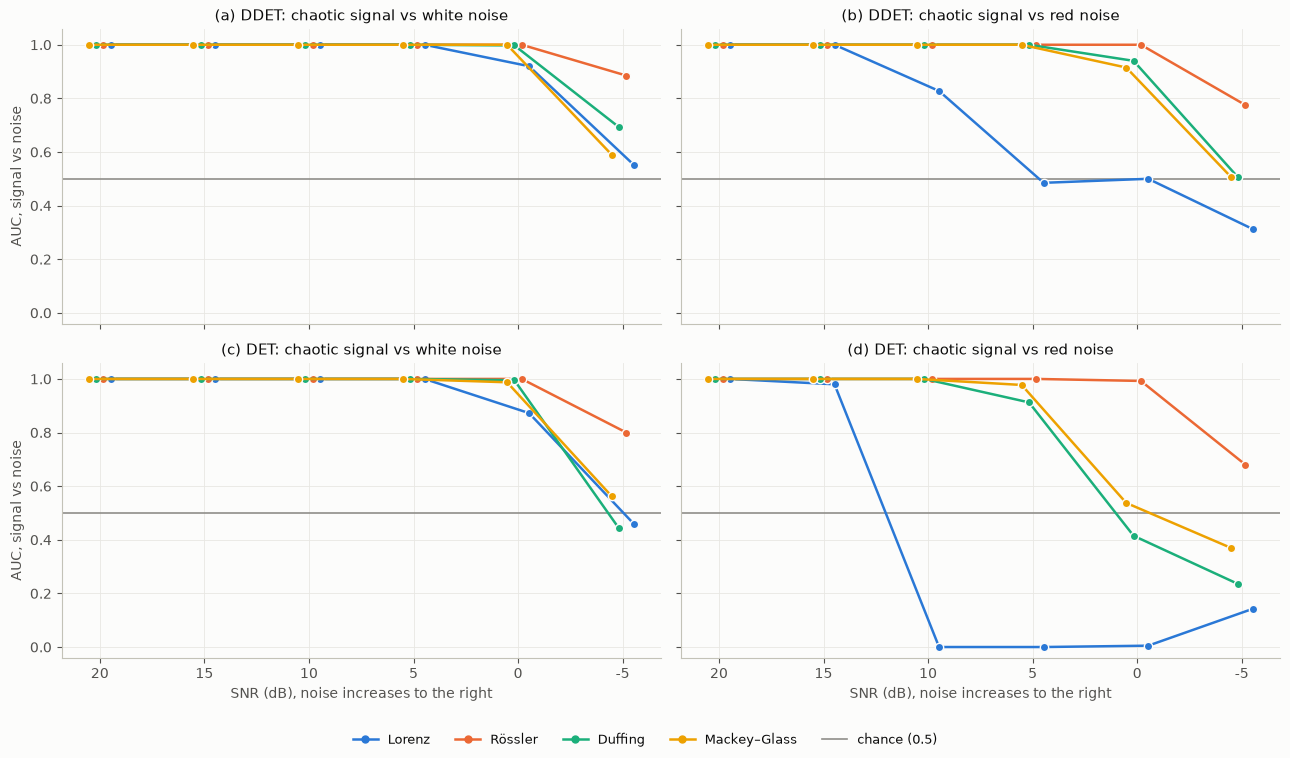

In [13]:
snrs_auc, K = [20, 15, 10, 5, 0, -5], 20

def auc_ab(a, b):                       # P(a > b) over all pairs, ties count half
    a, b = np.asarray(a)[:, None], np.asarray(b)[None, :]
    return float(np.mean((a > b) + 0.5 * (a == b)))

t0 = time.time()
auc_res = {}
for name, c in SYSTEMS.items():
    m, tau, tau_m = c["m"], c["tau"], c["tau_m"]
    n_raw = N + (m - 1) * tau
    white = np.c_[res[name]["base"]["values"], res[name]["det_base"]["values"]]     # (20, 2): DDET, DET of B2's white noise
    long = c["sim"](c["chaos"], n_raw * K)
    segs = [xr.zscore(long[i * n_raw:(i + 1) * n_raw]) for i in range(K)]
    for snr in snrs_auc:
        noisy = [xr.add_noise(s, snr, seed=100 * i + 7) for i, s in enumerate(segs)]
        sig = np.array([lm2p(s, m, tau, tau_m) for s in noisy])
        phi = float(np.mean([np.corrcoef(s[:-1], s[1:])[0, 1] for s in noisy]))
        rng = np.random.default_rng(1)
        red = np.array([lm2p(ar1(phi)(rng, n_raw), m, tau, tau_m) for _ in range(K)])
        auc_res[(name, snr)] = dict(phi=phi, white=[auc_ab(sig[:, j], white[:, j]) for j in (0, 1)],
                                    red=[auc_ab(sig[:, j], red[:, j]) for j in (0, 1)], sig_mean=sig.mean(0), red_mean=red.mean(0))
print(f"done in {time.time() - t0:.0f} s")

fig, axes = plt.subplots(2, 2, figsize=(13, 7.6), sharex=True, sharey=True)
panels = [("white", 0, "(a) DDET: chaotic signal vs white noise"), ("red", 0, "(b) DDET: chaotic signal vs red noise"),
          ("white", 1, "(c) DET: chaotic signal vs white noise"), ("red", 1, "(d) DET: chaotic signal vs red noise")]
for ax, (null, j, title) in zip(axes.flat, panels):
    ax.axhline(0.5, color=GREY, lw=1.2)
    for i, name in enumerate(SYSTEMS):
        y = [auc_res[(name, s)][null][j] for s in snrs_auc]
        ax.plot(np.array(snrs_auc) + 0.35 * (i - 1.5), y, color=SYSC[name], marker="o", ms=6, mec="#fcfcfb", mew=1)
    ax.set_xticks(snrs_auc, [str(v) for v in snrs_auc])
    ax.set_title(title)
axes[0, 0].invert_xaxis()                                           # x is shared, so all panels flip
axes[0, 0].set_ylim(-0.04, 1.06)
for ax in axes[1]:
    ax.set_xlabel("SNR (dB), noise increases to the right")
for ax in axes[:, 0]:
    ax.set_ylabel("AUC, signal vs noise")
handles = [Line2D([], [], color=SYSC[n], marker="o", label=n) for n in SYSTEMS] + [Line2D([], [], color=GREY, lw=1.2, label="chance (0.5)")]
fig.legend(handles=handles, loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.05, 1, 1))

cols = "".join(f"{str(s) + ' dB':>11s}" for s in snrs_auc)
for null, label in [("white", "white noise"), ("red", "red noise")]:
    print(f"\nAUC against {label}, DDET/DET")
    print(f"   {'':13s}{cols}")
    for name in SYSTEMS:
        print(f"   {name:13s}" + "".join(f"  {auc_res[(name, s)][null][0]:.2f}/{auc_res[(name, s)][null][1]:.2f}" for s in snrs_auc))
for j, label, fmt in [(0, "DDET", "+.2f"), (1, "DET", ".3f")]:
    print(f"\nmean {label}, signal/red noise")
    print(f"   {'':13s}" + "".join(f"{str(s) + ' dB':>13s}" for s in snrs_auc))
    for name in SYSTEMS:
        print(f"   {name:13s}" + "".join(f"{format(auc_res[(name, s)]['sig_mean'][j], fmt) + '/' + format(auc_res[(name, s)]['red_mean'][j], fmt):>13s}" for s in snrs_auc))
print("\nlag-1 autocorrelation φ of the noisy signal (used for the red noise)")
print(f"   {'':13s}{cols}")
for name in SYSTEMS:
    print(f"   {name:13s}" + "".join(f"{auc_res[(name, s)]['phi']:11.3f}" for s in snrs_auc))

* **Chaotic signals keep a positive distance down to 5 dB**, from +0.37 (Lorenz) to +0.96 (Rössler). At 10 dB all four are still +0.6 to +1.8 above white noise, many white-noise standard deviations. The question "deterministic or noise?" can therefore be answered at much higher noise levels than "periodic or chaotic?".
* **Periodic signals fall much faster.** Between 25 and 15 dB they lose most of their distance: Lorenz goes from +4.19 to +1.58, Duffing from +5.27 to +2.00. Rössler and Mackey–Glass hold up longest (+6.19 and +6.08 at 20 dB).
* At 10 dB, periodic and chaotic distances are within ≈ 0.5 of each other for every system. That is consistent with the paper's conclusion that DDET stops telling the regimes apart below ≈ 15 dB.b

### B6. Summary table

In [14]:
hdr = (f"{'':13s}{'white noise':>13s}{'model':>7s}{'surrogates':>12s} | {'ΔDDET chaotic':>17s} | {'ΔDDET periodic':>17s} |"
       f"{'closest chaotic':>16s}{'AUC':>6s}")
sub = f"{'':13s}{'mean ± sd':>13s}{'':7s}{'mean ± sd':>12s} | {'clean':>8s}{'20 dB':>9s} | {'clean':>8s}{'20 dB':>9s} |{'20 dB (sd)':>16s}{'20 dB':>6s}"
print(hdr); print(sub); print("-" * len(hdr))
for name, r in res.items():
    b, s, per = r["base"], r["surr"], r["periodic"]
    dc, dn = r["clean"] - b["mean"], r["noisy"] - b["mean"]
    closest = dn[~per].min()
    print(f"{name:13s}{b['mean']:+7.2f} ± {b['sd']:.2f}{b['theory']:+7.2f}{s['mean']:+6.2f} ± {s['sd']:.2f} | "
          f"{np.median(dc[~per]):+8.2f}{np.median(dn[~per]):+9.2f} | {np.median(dc[per]):+8.2f}{np.median(dn[per]):+9.2f} |"
          f"{closest:+8.2f} ({closest / b['sd']:4.0f}){auc(r['noisy'], per):6.2f}")
print("\nΔDDET columns are medians over the sweep. 'closest chaotic' is the smallest ΔDDET of any chaotic value with 20 dB noise,"
      "\nalso in units of the white-noise sd. AUC: probability that a periodic value scores higher than a chaotic one.")

               white noise  model  surrogates |     ΔDDET chaotic |    ΔDDET periodic | closest chaotic   AUC
                 mean ± sd          mean ± sd |    clean    20 dB |    clean    20 dB |      20 dB (sd) 20 dB
-------------------------------------------------------------------------------------------------------------
Lorenz         -1.05 ± 0.07  -1.05 -1.00 ± 0.05 |    +1.77    +1.51 |    +7.46    +2.39 |   +1.33 (  19)  0.98
Rössler        -0.80 ± 0.05  -0.77 -0.74 ± 0.04 |    +2.97    +2.88 |    +7.26    +6.51 |   +1.88 (  39)  0.97
Duffing        -1.05 ± 0.07  -1.02 -0.91 ± 0.07 |    +1.80    +1.79 |    +7.29    +6.64 |   +1.56 (  23)  0.99
Mackey–Glass   -1.01 ± 0.08  -1.01 -0.94 ± 0.05 |    +2.00    +1.78 |    +7.71    +5.98 |   +1.36 (  18)  0.99

ΔDDET columns are medians over the sweep. 'closest chaotic' is the smallest ΔDDET of any chaotic value with 20 dB noise,
also in units of the white-noise sd. AUC: probability that a periodic value scores higher than a chaotic

### B7. Conclusions

1. **The white-noise DDET is not a constant.** ≈ −1 holds only for the paper's settings. It follows ≈ ln(ws² · d_max(d_max+1)/2 · RR) and spans about −2.5 … +2.2 over common settings. Compute it for your settings (`xr.ddet_baseline`) and report ΔDDET.
2. **Against matched baselines, all four chaotic systems are clearly deterministic.** With 20 dB noise their ΔDDET is ≈ +1.5 … +2.9, which is 4–18 times the diagonal structure of noise, and they are still above noise at 5 dB.
3. **DET is also far from white noise, but carries less information.** It saturates at ≈ 0.9 for both regimes without noise and loses 56–75 % of its distance at 20 dB, except for Rössler. Its periodic–chaotic AUC is 0.76–0.98, against 0.97–0.99 for DDET (B3).
4. **ΔDDET also orders the dynamics**: periodic ≫ phase-coherent chaos (Rössler) > other chaos > noise. Absolute levels differ per system and per setting, so compare within one analysis.
5. **White noise is the easy reference.** Against white noise both DET and DDET recognise all four chaotic signals down to ≈ 0 dB. Noise with memory raises the baseline (A4b): against AR(1) red noise DDET still recognises Rössler, Duffing and Mackey–Glass down to ≈ 0 dB and Lorenz down to ≈ 15 dB, while DET fails earlier, for Lorenz already at 10 dB (B5). For real data, check against coloured surrogates before claiming determinism.